# Lab 7 · Train a Vision Transformer (ViT) on CIFAR-10 + mini project: ViT image classifier

**Course lab:** `CV-Week3-Lecture7.ipynb` (copy in `course-files/labs/`). Exercise: *"Train ViT on CIFAR-10"* with `timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=10)`. Mini project: *"Image classifier with ViT"*.

**What you will learn**
- How `timm` builds a pretrained ViT, and what `vit_base_patch16_224` means (Base size, 16×16 patches, 224×224 input).
- Why the course **resizes 32×32 CIFAR images to 224×224**, and what that costs.
- Why **fully fine-tuning ViT-Base (86 million parameters) is a GPU job**: we measure it.
- A CPU-friendly version of the same idea: **frozen pretrained ViT + a new linear head**.
- The key ViT lesson, measured on the same small dataset: **pretrained ViT ≫ CNN from scratch > ViT from scratch**. Transformers need lots of data or pretraining.

**Run time.** 24 minutes on the 4-core CPU this notebook was built on, which was shared with other heavy jobs at the time (measured: see the last code cell). Most of it is pushing 1,500 images through ViT-Base. An idle machine will be faster. On a Colab GPU the same steps should take only a few minutes. The course's full fine-tuning (flag `FULL_FINETUNE = True`) is a GPU job: our rough estimate for a T4 is 10–20 minutes per epoch on all 50,000 images (not measured; we could not run it here).

## 0 · Theory in 60 seconds

Full theory: [notes/07_attention_and_vision_transformers.md](../notes/07_attention_and_vision_transformers.md) and the notebook [07_vision_transformers_attention.ipynb](../notebooks/07_vision_transformers_attention.ipynb), where we build attention and a mini-ViT by hand.

1. **Patches → tokens.** Cut the image into 16×16 patches. A 224×224 image gives 14 × 14 = **196 patches**. Each patch (16·16·3 = 768 numbers) is mapped by a linear layer to a 768-long **embedding**.
2. **[CLS] token + position embeddings.** A learnable extra token is prepended (197 tokens), and a learned **position embedding** is added so the model knows where each patch came from.
3. **Transformer encoder** (12 blocks in ViT-Base): **multi-head self-attention** lets every token look at every other token (`softmax(Q·Kᵀ/√d)·V`), then an MLP; each with a residual connection + LayerNorm.
4. **Classification:** the final [CLS] token → `head` = `Linear(768 → num_classes)`.

**The catch:** ViT has almost no built-in assumptions about images (CNNs assume locality). So it needs **huge datasets** (ImageNet-21k with 14 M images, or JFT-300M) to learn them, or a model pretrained on such data. That is exactly what this lab measures.

In [1]:
%matplotlib inline
import os, time, urllib.request
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")    # harmless notice from timm's progress bar
import timm                     # PyTorch Image Models:  pip install timm

# While this notebook was built, other jobs shared the same 4-core CPU, so we limit PyTorch to 2 threads.
# On your own computer you can delete this line: PyTorch then uses all your cores.
torch.set_num_threads(2)
NOTEBOOK_START = time.time()
torch.manual_seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| timm", timm.__version__, "| device:", device)

torch 2.14.1+cu130 | timm 1.0.30 | device: cpu


## 1 · Setup: CIFAR-10 loader (the course's first cell)

The course's transform:

| Line | Why |
|---|---|
| `transforms.Resize((224,224))` | `vit_base_patch16_224` was pretrained on **224×224** images and its position embeddings are for exactly **14×14 = 196 patches**. A 32×32 CIFAR image would give only 2×2 = 4 patches of 16×16, so we blow it up 7× (each 16×16 patch then covers a blurry ~2.3×2.3 pixels of the original). |
| `transforms.Normalize([0.5,0.5,0.5],[0.5,0.5,0.5])` | → values in −1…1. Correct for this model: these ViT weights were trained with mean = std = 0.5 (timm stores this in `model.pretrained_cfg`). |
| `batch_size=32` | 224×224 images through an 86 M-parameter model use a lot of memory |

**Data routes** (same as Lab 1): the official `torchvision.datasets.CIFAR10(download=True)` first; if the Toronto server cannot be reached (as on our build machine), the same images as JPG files from a GitHub mirror. The executed output says which route ran.

**Subset.** ViT-Base is slow on a CPU (we measure it below), so this lab uses **100 training + 50 test images per class (1,000 + 500)**. That is also a realistic "small dataset" setting, where the pretraining question matters most.

In [2]:
N_TRAIN_PER_CLASS = 100     # full dataset: 5000
N_TEST_PER_CLASS = 50       # full dataset: 1000
DIR_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']  # CIFAR-10 label order
MIRROR = "https://raw.githubusercontent.com/YoongiKim/CIFAR-10-images/master"

def first_n_per_class(targets, n):
    idx, seen = [], {}
    for i, t in enumerate(targets):
        if seen.get(t, 0) < n:
            idx.append(i); seen[t] = seen.get(t, 0) + 1
    return idx

class CifarJpgFolder(torch.utils.data.Dataset):
    """Fallback dataset: data/cifar10_jpg/<split>/<class>/0000.jpg ..."""
    def __init__(self, root, n_per_class, transform=None):
        self.samples = [(f"{root}/{c}/{i:04d}.jpg", label) for label, c in enumerate(DIR_NAMES) for i in range(n_per_class)]
        self.targets = [label for _, label in self.samples]
        self.classes = DIR_NAMES
        self.transform = transform
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, i):
        path, label = self.samples[i]
        img = Image.open(path).convert("RGB")
        return (self.transform(img) if self.transform else img), label

def download_mirror(split, n_per_class, root="./data/cifar10_jpg"):
    jobs = [(f"{MIRROR}/{split}/{c}/{i:04d}.jpg", f"{root}/{split}/{c}/{i:04d}.jpg") for c in DIR_NAMES for i in range(n_per_class)]
    jobs = [(u, p) for u, p in jobs if not os.path.exists(p)]
    def fetch(job):
        url, path = job
        os.makedirs(os.path.dirname(path), exist_ok=True)
        for attempt in range(3):
            try:
                urllib.request.urlretrieve(url, path + ".part"); os.replace(path + ".part", path); return
            except Exception as e:
                err = e
        raise err
    t = time.time()
    with ThreadPoolExecutor(32) as pool:
        list(pool.map(fetch, jobs))
    print(f"  mirror: {split}: downloaded {len(jobs)} new files in {time.time() - t:.0f}s")
    return f"{root}/{split}"

def load_cifar10(train_transform, test_transform, verbose=True):
    try:
        trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transform)
        testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=test_transform)
        classes = trainset.classes
        trainset = torch.utils.data.Subset(trainset, first_n_per_class(trainset.targets, N_TRAIN_PER_CLASS))
        testset = torch.utils.data.Subset(testset, first_n_per_class(testset.targets, N_TEST_PER_CLASS))
        if verbose: print("DATA ROUTE: official torchvision CIFAR10 download")
    except Exception as e:
        if verbose:
            print("Official CIFAR-10 download failed:", type(e).__name__, str(e)[:80])
            print("DATA ROUTE: fallback = CIFAR-10 JPG mirror on GitHub")
        trainset = CifarJpgFolder(download_mirror("train", N_TRAIN_PER_CLASS), N_TRAIN_PER_CLASS, train_transform)
        testset = CifarJpgFolder(download_mirror("test", N_TEST_PER_CLASS), N_TEST_PER_CLASS, test_transform)
        classes = DIR_NAMES
    return trainset, testset, classes

def targets_of(ds):
    # labels of a dataset, for both routes (a Subset of CIFAR10, or our JPG folder)
    return list(ds.targets) if hasattr(ds, "targets") else [ds.dataset.targets[i] for i in ds.indices]

# ---- the course's cell ----
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5,0.5,0.5],[0.5,0.5,0.5])
])

trainset, testset, classes = load_cifar10(transform, transform)
trainloader = DataLoader(trainset, batch_size=32, shuffle=True)
testloader = DataLoader(testset, batch_size=32, shuffle=False)

print("Classes:", classes)
print(f"train: {len(trainset)} images | test: {len(testset)} images")
x, y = trainset[0]
print("one transformed image:", tuple(x.shape), f"(was 32x32) -> 224/16 = {224 // 16} patches per side = {(224 // 16) ** 2} patches")

Official CIFAR-10 download failed: URLError <urlopen error Tunnel connection failed: 403 Forbidden>
DATA ROUTE: fallback = CIFAR-10 JPG mirror on GitHub


  mirror: train: downloaded 1000 new files in 8s


  mirror: test: downloaded 500 new files in 4s
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
train: 1000 images | test: 500 images
one transformed image: (3, 224, 224) (was 32x32) -> 224/16 = 14 patches per side = 196 patches


## 2 · Exercise: "Train ViT on CIFAR-10"

### 2.1 Loading the pretrained ViT: official route and fallback

```python
model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=10)
```
- **`'vit_base_patch16_224'`**: ViT-**Base** (12 blocks, 768-dim embeddings, 12 attention heads, ≈ 86 M parameters), **patch 16**, input **224**.
- **`pretrained=True`**: download ImageNet weights. In `timm` this argument is current (unlike torchvision's deprecated `pretrained=`).
- **`num_classes=10`**: timm loads every pretrained weight **except** the final `head`, which it replaces with a new, randomly initialised `Linear(768 → 10)`. That's the timm equivalent of Lab 1's `classifier[6] = ...` and Lab 2's `fc = ...`.

`timm` downloads the weights from the **Hugging Face Hub**, which the build machine cannot reach. Fallback: the **original ViT-B/16 weights released by the ViT authors** (pretrained on ImageNet-21k, fine-tuned on ImageNet-1k at 224×224), converted to PyTorch by timm's author and published on GitHub. Their layer names match timm's model exactly. These were timm's default weights for this model name in earlier versions; today's default (`augreg2_in21k_ft_in1k`) is a newer training recipe of the same architecture. Both use mean = std = 0.5.

The fallback loads them in three steps: create the model with random weights → `load_state_dict` → `reset_classifier(10)` to swap in a new 10-class head. The result is the same as what the course's one-liner does.

In [3]:
FALLBACK_URL = "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-vitjx/jx_vit_base_p16_224-80ecf9dd.pth"

def load_pretrained_vit(num_classes=10):
    try:
        model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=num_classes)
        print("WEIGHTS ROUTE: official timm / Hugging Face download")
        return model, None
    except Exception as e:
        print("Official timm download failed:", type(e).__name__, str(e)[:80])
        model = timm.create_model('vit_base_patch16_224', pretrained=False)          # random weights, 1000-class head
        t = time.time()
        state = torch.hub.load_state_dict_from_url(FALLBACK_URL, model_dir="data/weights", map_location="cpu", progress=False)
        print(f"  checkpoint loaded in {time.time() - t:.0f}s;", "load_state_dict:", model.load_state_dict(state))
        print("WEIGHTS ROUTE: fallback = original ViT-B/16 ImageNet weights from GitHub")
        imagenet_model = model
        return model, imagenet_model

model, imagenet_model = load_pretrained_vit()

Official timm download failed: ProxyError 403 Forbidden


Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-vitjx/jx_vit_base_p16_224-80ecf9dd.pth" to data/weights/jx_vit_base_p16_224-80ecf9dd.pth


  checkpoint loaded in 3s; load_state_dict: <All keys matched successfully>
WEIGHTS ROUTE: fallback = original ViT-B/16 ImageNet weights from GitHub


**Sanity check (fallback route only).** Before replacing the head, the fallback model still has its 1000 ImageNet outputs, so we can check that the weights are real. ImageNet has classes like "speedboat", "moving van" and "sorrel" (a chestnut horse), so some upscaled CIFAR images should get sensible guesses. Others won't: a 32×32 image blown up to 224×224 is very blurry, and many ImageNet classes are very specific. Then we call `reset_classifier(10)`.

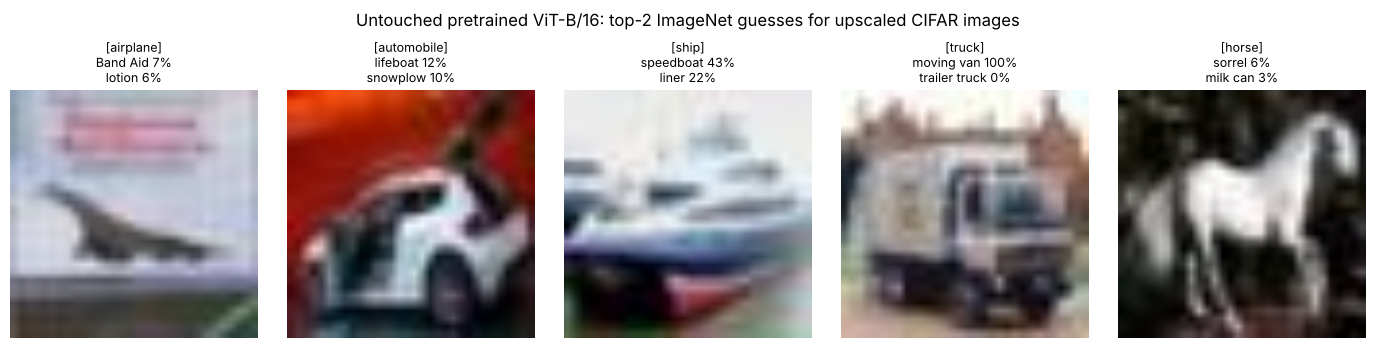

head: Linear(in_features=768, out_features=10, bias=True)
parameters: 85.8 M | pretrained_cfg mean/std: (0.5, 0.5, 0.5), (0.5, 0.5, 0.5)


In [4]:
imagenet_names = torchvision.models.ViT_B_16_Weights.IMAGENET1K_V1.meta["categories"]   # 1000 ImageNet names, shipped with torchvision
if imagenet_model is not None:
    imagenet_model.eval()
    test_targets = targets_of(testset)
    picks = [test_targets.index(k) for k in (0, 1, 8, 9, 7)]      # first plane, car, ship, truck, horse
    batch = torch.stack([testset[i][0] for i in picks])
    with torch.no_grad():
        p = torch.softmax(imagenet_model(batch), 1)
    plt.figure(figsize=(14, 3.3))
    for k, i in enumerate(picks):
        top = p[k].topk(2)
        plt.subplot(1, 5, k + 1); plt.imshow((batch[k] / 2 + 0.5).permute(1, 2, 0).clamp(0, 1)); plt.axis("off")
        plt.title(f"[{classes[test_targets[i]]}]\n" + "\n".join(f"{imagenet_names[j][:18]} {v:.0%}" for v, j in zip(top.values, top.indices)), fontsize=9)
    plt.suptitle("Untouched pretrained ViT-B/16: top-2 ImageNet guesses for upscaled CIFAR images", y=1.04); plt.tight_layout(); plt.show()
    model.reset_classifier(10)                     # new random Linear(768 -> 10), as num_classes=10 does
print("head:", model.head)
print(f"parameters: {sum(p.numel() for p in model.parameters())/1e6:.1f} M | pretrained_cfg mean/std: {model.pretrained_cfg.get('mean')}, {model.pretrained_cfg.get('std')}")

### 2.2 Inside the model: from image to 197 tokens

The same steps as the theory, on the real model:

In [5]:
model.eval()
x = torch.stack([testset[0][0]])                                    # (1, 3, 224, 224)
with torch.no_grad():
    patches = model.patch_embed(x)                                  # conv 16x16 stride 16 = "cut into patches + linear map"
    print("image                  :", tuple(x.shape))
    print("patch_embed (tokens)   :", tuple(patches.shape), " -> 196 patches, each a 768-long vector")
    print("cls_token              :", tuple(model.cls_token.shape))
    print("pos_embed              :", tuple(model.pos_embed.shape), " -> one position vector per token (196 + CLS)")
    tokens = model.forward_features(x)
    print("after 12 encoder blocks:", tuple(tokens.shape))
    print("CLS token -> head      :", tuple(model.forward_head(tokens, pre_logits=True).shape), "->", tuple(model.forward_head(tokens).shape))
print(f"number of encoder blocks: {len(model.blocks)}, attention heads per block: {model.blocks[0].attn.num_heads}")

image                  : (1, 3, 224, 224)
patch_embed (tokens)   : (1, 196, 768)  -> 196 patches, each a 768-long vector
cls_token              : (1, 1, 768)
pos_embed              : (1, 197, 768)  -> one position vector per token (196 + CLS)


after 12 encoder blocks: (1, 197, 768)
CLS token -> head      : (1, 768) -> (1, 10)
number of encoder blocks: 12, attention heads per block: 12


### 2.3 The course's full fine-tuning: how long would it take here?

The course trains **all 86 M parameters** (`optim.Adam(model.parameters(), lr=0.0001)`) for 2 epochs on 50,000 images resized to 224×224. `lr = 0.0001` is 10× smaller than in Labs 1–2 on purpose: when fine-tuning pretrained weights you only want to *nudge* them, because big steps would destroy what was learned.

Rather than guess, we **time one real training step** (forward + backward + Adam update) on a batch of 8 and extrapolate:

In [6]:
FULL_FINETUNE = False      # True = run the course's loop (needs a GPU, e.g. Google Colab)

model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

# time 2 real training steps on 8 images (the first step includes warm-up)
model.train()
xb, yb = next(iter(DataLoader(trainset, batch_size=8)))
for step in range(2):
    t = time.time()
    optimizer.zero_grad()
    loss = criterion(model(xb.to(device)), yb.to(device))
    loss.backward()
    optimizer.step()
    step_time = time.time() - t
per_img = step_time / 8
print(f"one training step on 8 images: {step_time:.1f}s  ->  {per_img*1000:.0f} ms per image")
print(f"estimated time for ONE epoch of the course (50,000 images) on this CPU: {per_img*50000/3600:.1f} hours")
print(f"... and for one epoch of our 1,000-image subset: {per_img*1000/60:.1f} minutes")

if FULL_FINETUNE:
    # ---- the course's training loop (unchanged) ----
    for epoch in range(1, 3):
        running_loss = 0.0
        for inputs, labels in trainloader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        print(f"Epoch {epoch}, Loss: {running_loss/len(trainloader):.4f}")
else:
    print("FULL_FINETUNE = False: skipping the course's full fine-tuning loop (set True on a GPU).")

one training step on 8 images: 17.9s  ->  2237 ms per image
estimated time for ONE epoch of the course (50,000 images) on this CPU: 31.1 hours
... and for one epoch of our 1,000-image subset: 37.3 minutes
FULL_FINETUNE = False: skipping the course's full fine-tuning loop (set True on a GPU).


### 2.4 The CPU-friendly version: frozen pretrained ViT + new linear head

This is **Lab 2's trick applied to a transformer**: freeze every pretrained weight and train only the new `head`. Because the backbone never changes, each image's 768-number [CLS] feature is always the same. So we compute it **once**, store it, and train the head on the stored features. That's mathematically the same as running the course's loop with a frozen backbone, but we pay the expensive ViT forward pass only once per image instead of once per epoch.

(Before extracting we reload the pretrained weights, so the single training step above leaves no trace.)

In [7]:
del optimizer, model                     # free the fine-tuning model and its Adam state (about 1 GB)
model, _ = load_pretrained_vit()
model.reset_classifier(10)
for param in model.parameters():
    param.requires_grad = False          # freeze everything ...
for param in model.head.parameters():
    param.requires_grad = True           # ... except the new head
model.to(device).eval()                  # eval(): always the right habit for testing / feature extraction
print(f"trainable: {sum(p.numel() for p in model.parameters() if p.requires_grad):,} of {sum(p.numel() for p in model.parameters()):,} parameters")

def extract_features(loader):
    feats, labels = [], []
    with torch.no_grad():
        for inputs, y in loader:
            f = model.forward_head(model.forward_features(inputs.to(device)), pre_logits=True)   # the [CLS] vector
            feats.append(f.cpu()); labels.append(y)
    return torch.cat(feats), torch.cat(labels)

t = time.time()
Ftr, Ytr = extract_features(trainloader)
Fte, Yte = extract_features(testloader)
vit_feature_time = time.time() - t
print(f"features: train {tuple(Ftr.shape)}, test {tuple(Fte.shape)} in {vit_feature_time:.0f}s "
      f"= {1000 * vit_feature_time / (len(Ftr) + len(Fte)):.0f} ms per image (inference only)")

Official timm download failed: ProxyError 403 Forbidden


  checkpoint loaded in 0s; load_state_dict: <All keys matched successfully>
WEIGHTS ROUTE: fallback = original ViT-B/16 ImageNet weights from GitHub
trainable: 7,690 of 85,806,346 parameters


features: train (1000, 768), test (500, 768) in 530s = 354 ms per image (inference only)


In [8]:
torch.manual_seed(0)
head = model.head                                    # the new Linear(768 -> 10)
opt_head = optim.Adam(head.parameters(), lr=0.001)
hist_vit = {"loss": [], "acc": []}
feat_loader = DataLoader(torch.utils.data.TensorDataset(Ftr, Ytr), batch_size=32, shuffle=True)
for epoch in range(1, 31):
    running_loss = 0.0
    for f, y in feat_loader:                         # the course's loop, on stored features
        opt_head.zero_grad()
        loss = criterion(head(f.to(device)), y.to(device))
        loss.backward()
        opt_head.step()
        running_loss += loss.item()
    with torch.no_grad():
        acc = 100 * (head(Fte.to(device)).argmax(1).cpu() == Yte).float().mean().item()
    hist_vit["loss"].append(running_loss / len(feat_loader)); hist_vit["acc"].append(acc)
    if epoch in (1, 2, 5, 10, 20, 30):
        print(f"Epoch {epoch:2d}, Loss: {hist_vit['loss'][-1]:.4f}, test accuracy: {acc:.1f}%")
acc_vit_pre = hist_vit["acc"][-1]

Epoch  1, Loss: 1.1075, test accuracy: 84.0%


Epoch  2, Loss: 0.3998, test accuracy: 84.8%


Epoch  5, Loss: 0.1903, test accuracy: 87.4%


Epoch 10, Loss: 0.0757, test accuracy: 88.0%


Epoch 20, Loss: 0.0255, test accuracy: 88.2%


Epoch 30, Loss: 0.0132, test accuracy: 88.2%


## 3 · Does pretraining matter? ViT from scratch vs CNN from scratch

Now the experiment that explains *why* the course loads `pretrained=True`. On the **same 1,000 training images** and the same 500 test images we train two small models **from random weights**, at CIFAR's native 32×32 (no resizing):

- **Tiny ViT**: timm's own `VisionTransformer` class, sized for 32×32 images: patch 4 → 8×8 = 64 patches + CLS, 96-dim embeddings, 4 blocks, 3 heads.
- **Small CNN**: VGG-style, 3 blocks of two 3×3 convs + BatchNorm + max-pool (as in Lab 1, but narrower).

Both have a similar number of parameters (printed below), get the same light augmentation (random crop + flip), Adam lr = 0.001, 30 epochs, cosine learning-rate schedule.

In [9]:
from timm.models.vision_transformer import VisionTransformer

def conv_bn_relu(c_in, c_out):
    return [nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True)]

def make_small_cnn():
    return nn.Sequential(
        *conv_bn_relu(3, 32), *conv_bn_relu(32, 32), nn.MaxPool2d(2),       # 32 -> 16
        *conv_bn_relu(32, 64), *conv_bn_relu(64, 64), nn.MaxPool2d(2),      # 16 -> 8
        *conv_bn_relu(64, 96), *conv_bn_relu(96, 96), nn.MaxPool2d(2),      # 8 -> 4
        nn.Flatten(), nn.Dropout(0.3), nn.Linear(96 * 4 * 4, 10))

def make_tiny_vit():
    return VisionTransformer(img_size=32, patch_size=4, num_classes=10, embed_dim=96, depth=4, num_heads=3, mlp_ratio=2.0)

small_tf_train = transforms.Compose([transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip(),
                                     transforms.ToTensor(), transforms.Normalize([0.5] * 3, [0.5] * 3)])
small_tf_test = transforms.Compose([transforms.ToTensor(), transforms.Normalize([0.5] * 3, [0.5] * 3)])
train32, test32, _ = load_cifar10(small_tf_train, small_tf_test, verbose=False)        # same images, kept at 32x32
train32_loader = DataLoader(train32, batch_size=64, shuffle=True)
test32_loader = DataLoader(test32, batch_size=100, shuffle=False)

for name, fn in [("tiny ViT", make_tiny_vit), ("small CNN", make_small_cnn)]:
    print(f"{name:9s}: {sum(p.numel() for p in fn().parameters())/1e6:.2f} M parameters")

  mirror: train: downloaded 0 new files in 0s
  mirror: test: downloaded 0 new files in 0s
tiny ViT : 0.31 M parameters
small CNN: 0.22 M parameters


In [10]:
def evaluate(net, loader):
    net.eval(); correct = 0; preds = []
    with torch.no_grad():
        for x, y in loader:
            p = net(x.to(device)).argmax(1).cpu()
            correct += (p == y).sum().item(); preds.append(p)
    return 100 * correct / len(loader.dataset), torch.cat(preds)

def train_from_scratch(net, epochs=30, name=""):
    torch.manual_seed(0)
    net.to(device)
    opt = optim.Adam(net.parameters(), lr=0.001)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    hist = {"loss": [], "acc": []}
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        net.train(); running = 0.0
        for x, y in train32_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); loss = criterion(net(x), y); loss.backward(); opt.step()
            running += loss.item()
        sched.step()
        acc, _ = evaluate(net, test32_loader)
        hist["loss"].append(running / len(train32_loader)); hist["acc"].append(acc)
        if epoch in (1, 5, 10, 20, 30):
            print(f"[{name}] Epoch {epoch:2d}, Loss: {hist['loss'][-1]:.4f}, test accuracy: {acc:.1f}%")
    hist["time"] = time.time() - t0
    print(f"[{name}] {hist['time']:.0f}s total, {hist['time']/epochs:.1f}s per epoch")
    return hist

torch.manual_seed(0); tiny_vit = make_tiny_vit()
hist_tvit = train_from_scratch(tiny_vit, name="tiny ViT, scratch")
torch.manual_seed(0); small_cnn = make_small_cnn()
hist_cnn = train_from_scratch(small_cnn, name="small CNN, scratch")

[tiny ViT, scratch] Epoch  1, Loss: 2.1804, test accuracy: 16.4%


[tiny ViT, scratch] Epoch  5, Loss: 1.9766, test accuracy: 24.4%


[tiny ViT, scratch] Epoch 10, Loss: 1.8648, test accuracy: 24.6%


[tiny ViT, scratch] Epoch 20, Loss: 1.6686, test accuracy: 32.2%


[tiny ViT, scratch] Epoch 30, Loss: 1.5527, test accuracy: 31.0%
[tiny ViT, scratch] 653s total, 21.8s per epoch


[small CNN, scratch] Epoch  1, Loss: 2.2214, test accuracy: 15.0%


[small CNN, scratch] Epoch  5, Loss: 1.5901, test accuracy: 39.2%


[small CNN, scratch] Epoch 10, Loss: 1.3352, test accuracy: 41.4%


[small CNN, scratch] Epoch 20, Loss: 0.8774, test accuracy: 51.2%


[small CNN, scratch] Epoch 30, Loss: 0.6761, test accuracy: 53.4%
[small CNN, scratch] 129s total, 4.3s per epoch


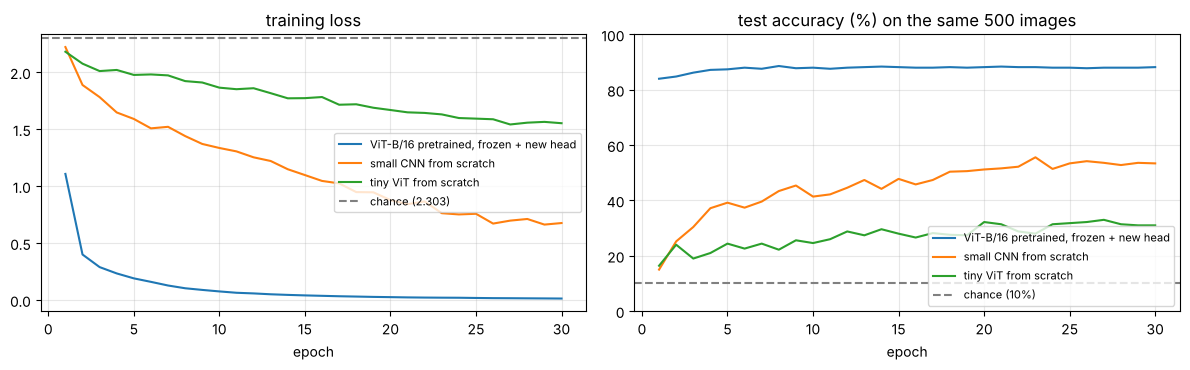

model (1,000 training images)            test acc    params   trained
ViT-B/16 pretrained, frozen + head          88.2%    85.8 M     7,690
small CNN from scratch                      53.4%    0.22 M       all
tiny ViT from scratch                       31.0%    0.31 M       all


In [11]:
acc_tvit, _ = evaluate(tiny_vit, test32_loader)
acc_cnn, _ = evaluate(small_cnn, test32_loader)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ep = range(1, 31)
ax[0].plot(ep, hist_vit["loss"], label="ViT-B/16 pretrained, frozen + new head")
ax[0].plot(ep, hist_cnn["loss"], label="small CNN from scratch")
ax[0].plot(ep, hist_tvit["loss"], label="tiny ViT from scratch")
ax[0].axhline(np.log(10), color="gray", ls="--", label="chance (2.303)")
ax[0].set_title("training loss"); ax[0].set_xlabel("epoch"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
ax[1].plot(ep, hist_vit["acc"], label="ViT-B/16 pretrained, frozen + new head")
ax[1].plot(ep, hist_cnn["acc"], label="small CNN from scratch")
ax[1].plot(ep, hist_tvit["acc"], label="tiny ViT from scratch")
ax[1].axhline(10, color="gray", ls="--", label="chance (10%)")
ax[1].set_ylim(0, 100); ax[1].set_title("test accuracy (%) on the same 500 images"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'model (1,000 training images)':40s}{'test acc':>9s}{'params':>10s}{'trained':>10s}")
print(f"{'ViT-B/16 pretrained, frozen + head':40s}{acc_vit_pre:8.1f}%{'85.8 M':>10s}{'7,690':>10s}")
print(f"{'small CNN from scratch':40s}{acc_cnn:8.1f}%{sum(p.numel() for p in small_cnn.parameters())/1e6:8.2f} M{'all':>10s}")
print(f"{'tiny ViT from scratch':40s}{acc_tvit:8.1f}%{sum(p.numel() for p in tiny_vit.parameters())/1e6:8.2f} M{'all':>10s}")

## 4 · Mini project: the ViT image classifier, evaluated

The classifier is the frozen ViT-B/16 + our trained head. The head was trained on stored features, and it *is* `model.head`, so `model(images)` now runs the complete pretrained ViT plus our new head on raw images. First the course's test loop (with **`model.eval()`** added) on the first 4 test batches, to check that the full model agrees with the stored-feature route. Running all 500 images again would cost several more CPU minutes for the same answer. Then per-class results and the confusion matrix for all 500 test images, from the stored features.

full model on the first 128 raw test images: accuracy 87.50%  (19s)
same predictions as the stored-feature route? True

Accuracy on the whole CIFAR-10 test subset (500 images): 88.20%

per-class accuracy:
  airplane    88.0%
  automobile  90.0%
  bird        86.0%
  cat         80.0%
  deer        94.0%
  dog         86.0%
  frog        90.0%
  horse       92.0%
  ship        88.0%
  truck       88.0%


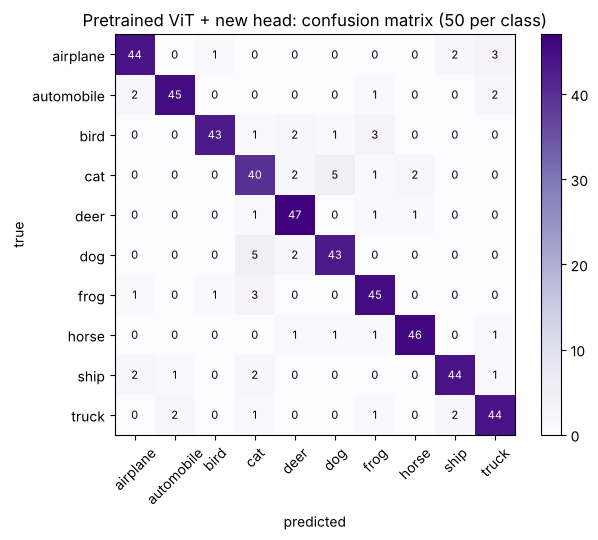

In [12]:
model.eval()
correct, total, all_pred = 0, 0, []
t = time.time()
with torch.no_grad():
    for b, (inputs, labels) in enumerate(testloader):
        if b == 4:                       # 4 batches x 32 = 128 images are enough for the check
            break
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        all_pred.append(predicted.cpu())
full_pred = torch.cat(all_pred)
with torch.no_grad():
    feat_pred = head(Fte[:total].to(device)).argmax(1).cpu()
print(f"full model on the first {total} raw test images: accuracy {100 * correct / total:.2f}%  ({time.time() - t:.0f}s)")
print(f"same predictions as the stored-feature route? {torch.equal(full_pred, feat_pred)}")

with torch.no_grad():
    pred = head(Fte.to(device)).argmax(1).cpu().numpy()
true = Yte.numpy()
print(f"\nAccuracy on the whole CIFAR-10 test subset ({len(true)} images): {100 * (pred == true).mean():.2f}%")

cm = np.zeros((10, 10), dtype=int)
for a, b in zip(true, pred):
    cm[a, b] += 1
print("\nper-class accuracy:")
for i, c in enumerate(classes):
    print(f"  {c:10s} {100 * cm[i, i] / cm[i].sum():5.1f}%")
plt.figure(figsize=(6.5, 5.5))
plt.imshow(cm, cmap="Purples")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xticks(range(10), classes, rotation=45); plt.yticks(range(10), classes)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Pretrained ViT + new head: confusion matrix (50 per class)")
plt.colorbar(fraction=0.046); plt.tight_layout(); plt.show()

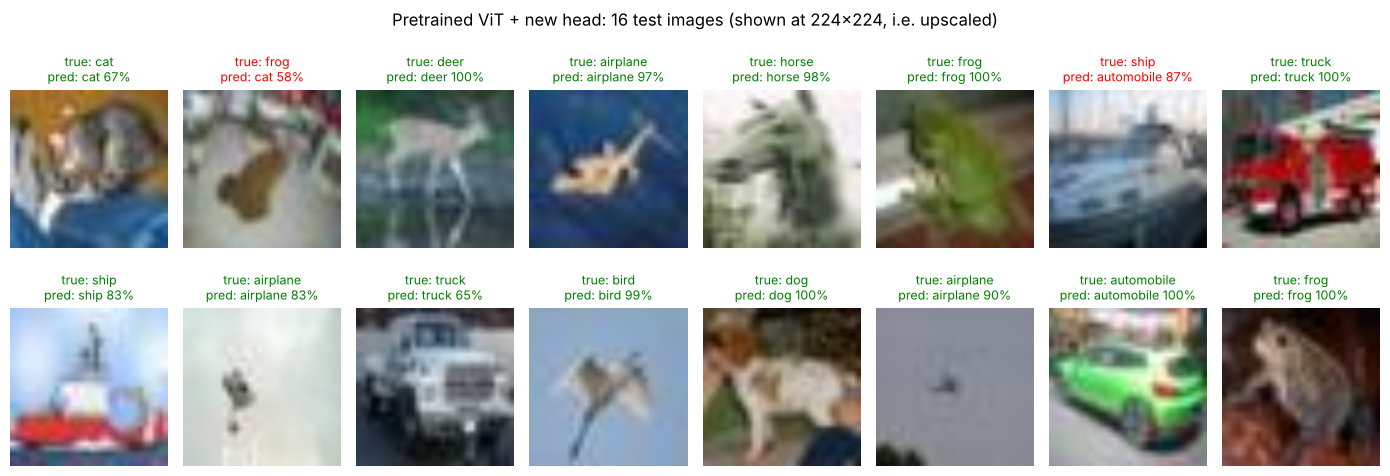

In [13]:
def imshow(img):
    img = img / 2 + 0.5          # correct un-normalisation here (we normalised with mean 0.5, std 0.5)
    npimg = img.numpy()
    plt.imshow(np.clip(np.transpose(npimg, (1, 2, 0)), 0, 1)); plt.axis("off")

rng = np.random.default_rng(0)
idx = rng.choice(len(testset), 16, replace=False)
with torch.no_grad():
    probs = torch.softmax(head(Fte[idx].to(device)), 1).cpu()      # stored features of these images -> same result as model(images)
conf, p = probs.max(1)
plt.figure(figsize=(14, 5.2))
for k, i in enumerate(idx):
    plt.subplot(2, 8, k + 1); imshow(testset[i][0])
    plt.title(f"true: {classes[Yte[i]]}\npred: {classes[p[k]]} {conf[k]:.0%}", fontsize=9, color="green" if p[k] == Yte[i] else "red")
plt.suptitle("Pretrained ViT + new head: 16 test images (shown at 224x224, i.e. upscaled)"); plt.tight_layout(); plt.show()

In [14]:
print(f"Total run time of this notebook: {(time.time() - NOTEBOOK_START) / 60:.1f} minutes")

Total run time of this notebook: 23.8 minutes


## 🔧 What we changed from the course notebook, and why

| Course code | Our version | Why |
|---|---|---|
| `CIFAR10(download=True)` only | official first, **GitHub JPG mirror fallback** | the build machine cannot reach the Toronto server (output shows the route) |
| full 50,000 / 10,000 images | **100 / 50 per class** | ViT-Base costs about 0.1–0.2 s per image on our CPU just for inference |
| `timm.create_model(..., pretrained=True, num_classes=10)` | same call first; **fallback**: original ViT-B/16 ImageNet weights from GitHub + `reset_classifier(10)` | Hugging Face is blocked on the build machine |
| full fine-tuning of all 86 M parameters, 2 epochs | kept behind `FULL_FINETUNE = False`; we **time one real step** instead | measured cost on this CPU: hours per epoch |
| (training of the whole model) | **frozen backbone + new head**, trained on stored [CLS] features | same model as freezing all but `head` in the course loop, at a fraction of the cost |
| test loop without `model.eval()` | `model.eval()` added | the right habit. timm's ViT-B has dropout layers but with probability 0 by default, so here it makes no numerical difference (unlike Labs 1–2) |
| batch prediction without `torch.no_grad()` | wrapped in `no_grad()` | no gradient graph for predictions |
| (not in course) | tiny ViT and small CNN **from scratch** on the same data | shows why ViTs need pretraining |
| `imshow`: `img / 2 + 0.5` | kept | correct here, because this lab normalises with mean = std = 0.5 |

## Results, honestly

Measured in the run above. All three models learned from the **same 1,000 CIFAR-10 training images** (100 per class) and were tested on the **same 500 test images**:

| Model | Test accuracy | Parameters (trained) | Input |
|---|---|---|---|
| **ViT-B/16 pretrained on ImageNet, frozen + new head** (CPU version of the course exercise) | **88.2 %** | 85.8 M (only 7,690 trained) | 224×224 (upscaled) |
| small CNN from scratch, 30 epochs | **53.4 %** | 0.22 M (all) | 32×32 |
| tiny ViT from scratch, 30 epochs | **31.0 %** | 0.31 M (all) | 32×32 |
| chance | 10 % | | |

What this shows:
- **Pretraining is what makes ViT work on small data.** The frozen pretrained ViT with a linear head reached 84.0 % after a single epoch and 88.2 % after 30, from just 100 images per class. Every class was at least 80 % (per-class list above).
- **From scratch, the transformer is the worst of the three** (31.0 %), clearly behind a CNN of similar size (53.4 %). With only 1,000 images the tiny ViT cannot learn what a CNN gets for free from its design (nearby pixels belong together, the same pattern can appear anywhere). This matches the original ViT paper, which found that ViTs trained only on ImageNet-sized data lag behind CNNs and pull ahead only after pretraining on much larger datasets (14 M to 300 M images).
- **The cost of ViT-Base on a CPU is real.** Feature extraction ran at about 354 ms per image (inference only). One full fine-tuning step measured 2237 ms per image, which extrapolates to about **31.1 hours for one epoch** of the course's full 50,000-image training. That's why the course's exercise needs a GPU, and why we ran the frozen-feature version instead.
- **The 224×224 resize is required, not optional:** the pretrained position embeddings expect 196 patches. But it means the model works on a blurry, 7× enlarged image, and it costs about 49× more pixels than the original.
- **Caveats:** our timings come from a CPU shared with other jobs, so expect them to be faster on your own machine. Only 500 test images (50 per class), so each class's accuracy moves in steps of 2 %. The fallback weights (original ViT-B/16) are not the same file as timm's current default, so with the official route your numbers will differ slightly. We did not run the full fine-tuning: no accuracy is claimed for it.

## Common errors and how to fix them

| Error / symptom | Cause | Fix |
|---|---|---|
| `AssertionError: Input height (32) doesn't match model (224)` | fed 32×32 images to `vit_base_patch16_224` | `transforms.Resize((224,224))`, as the course does (or create the model with `img_size=32` and train from scratch) |
| `CUDA out of memory` | ViT-Base + 224×224 + batch 32 + full fine-tuning | `batch_size=16` or `8`; mixed precision (`torch.autocast("cuda")`); or freeze the backbone |
| `ProxyError` / `LocalEntryNotFoundError` / `OSError` when `pretrained=True` | no access to huggingface.co | the notebook falls back to the GitHub checkpoint; or download the weights elsewhere and pass `pretrained_cfg_overlay=dict(file='path')` |
| `ModuleNotFoundError: No module named 'timm'` | timm not installed | `pip install timm` |
| `size mismatch for head.weight: [1000, 768] vs [10, 768]` | loading a 1000-class checkpoint into a 10-class model | load into the 1000-class model first, then `reset_classifier(10)` (as our fallback does) |
| training extremely slow | running ViT-Base on a CPU | use a GPU (Colab) or frozen features as in 2.4 |
| accuracy changes between runs of the test loop | forgot `model.eval()` in a model with active dropout or BatchNorm | `model.eval()` before testing |
| ViT from scratch stuck at low accuracy | not enough data for a transformer | use pretrained weights, more data, stronger augmentation, or a CNN |

## Try this yourself

1. **More data for the head.** Set `N_TRAIN_PER_CLASS = 300`. How much does the pretrained ViT improve? And the from-scratch models?
2. **Full fine-tuning on a GPU.** On Colab set `FULL_FINETUNE = True` (and `N_TRAIN_PER_CLASS = 5000`). Compare with the frozen version. The course reports only the loss, so add the test loop after it.
3. **CNN features instead.** Replace ViT with `timm.create_model('resnet50', pretrained=True, num_classes=0)` (gives 2048-dim features) and repeat section 2.4. Which pretrained backbone gives better features for CIFAR?
4. **Patch size.** Make the tiny ViT use `patch_size=8` (16 tokens) or `patch_size=2` (256 tokens). Accuracy vs speed?
5. **Look at attention.** Notebook [07](../notebooks/07_vision_transformers_attention.ipynb) builds attention by hand; try visualising `model.blocks[-1].attn` on one of these images.

## Run it on Google Colab with a GPU

1. Upload the notebook to [colab.research.google.com](https://colab.research.google.com); **Runtime → Change runtime type → T4 GPU**.
2. Delete the `torch.set_num_threads(2)` line. `timm` is usually pre-installed; if not, `!pip install timm`.
3. Run all. Both official downloads work there, so the outputs will say `DATA ROUTE: official` and `WEIGHTS ROUTE: official timm`.
4. Now the course's real exercise is affordable: `FULL_FINETUNE = True`. Our rough estimate is 10–20 minutes per epoch on 50,000 images with a T4 at batch size 32 (estimated from the GPU's compute, not measured). Start with `N_TRAIN_PER_CLASS = 1000` to see results sooner.

## Viva questions (with short model answers)

1. **How does ViT turn an image into a sequence?** It cuts the image into fixed-size patches (16×16), flattens each and projects it linearly to an embedding. Each patch is one token.
2. **How many tokens does `vit_base_patch16_224` use?** (224/16)² = 196 patch tokens + 1 [CLS] token = 197, each 768-dimensional.
3. **Why does the course resize CIFAR from 32×32 to 224×224?** The pretrained model expects 224×224, matching its 196 learned position embeddings (and timm checks the size). The cost: about 49× more pixels and far more compute per image, and the upscaled patches are blurry.
4. **What is self-attention?** Each token makes a query, key and value. Attention weights = softmax(Q·Kᵀ/√d) say how much each token looks at every other token, and the output is the weighted sum of values. It captures long-range relations from the first layer.
5. **Why multi-head attention?** Several attention heads in parallel, each with its own Q/K/V projections, so different heads can focus on different relationships. ViT-Base has 12 heads.
6. **What is the [CLS] token?** A learnable token prepended to the patches. After the encoder, its output summarises the whole image and is fed to the classification head.
7. **Why position embeddings?** Attention treats tokens as an unordered set. Position embeddings tell the model where each patch was.
8. **What does `num_classes=10` do in `timm.create_model`?** It keeps all pretrained weights except the final head, which becomes a new random `Linear(768, 10)`.
9. **Why lr = 0.0001 for ViT fine-tuning instead of 0.001?** Fine-tuning should only nudge pretrained weights. Large steps destroy the pretrained features, and transformers are especially sensitive to the learning rate.
10. **Why did the tiny ViT trained from scratch do worse than the small CNN on 1,000 images?** ViT lacks the CNN's built-in assumptions (locality, translation equivariance) and must learn them from data. With little data it cannot, so it overfits or underfits. This is why ViTs need huge datasets or pretraining.
11. **Why did the frozen pretrained ViT win by so much?** Its features were learned from millions of images (ImageNet-21k + ImageNet-1k). Only the 7,690-parameter head had to be learned from our 1,000 images.
12. **Feature extraction vs full fine-tuning?** Feature extraction: freeze the backbone and train only the head (cheap, works with little data). Full fine-tuning: update all weights with a small lr (better accuracy with enough data, needs a GPU).
13. **CNN vs ViT in one line each?** CNN: local filters, strong image assumptions, data-efficient. ViT: global attention from layer 1, few assumptions, needs lots of data but scales very well.
14. **Why can we cache features in 2.4?** The frozen backbone gives the same output for the same image every epoch, so computing it once is mathematically identical to recomputing it each epoch (no augmentation, model in eval mode).
15. **What is the computational problem of attention?** Its cost grows with the **square** of the number of tokens (every token attends to every token). Smaller patches or bigger images quickly become expensive.